In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt



In [2]:
cols_needed = ['prod_name', 'product_group_name', 'product_type_name', 'price']
df = pd.read_csv('/Users/dyamond/Documents/projects/fashion-analytics/data/processed/merged_cleaned_2019.csv', usecols=cols_needed)

In [3]:
print(df.shape)
df.head()

(16396930, 4)


,prod_name,product_group_name,product_type_name,price
0,Bilbo denim,Garment Upper body,Jacket,0.045763
1,Curvy Jeggings HW Ankle,Garment Lower body,Trousers,0.033881
2,Empire HW wide leg denim,Garment Lower body,Trousers,0.061000
3,Shark Boxy Sweater,Garment Upper body,Sweater,0.015237
4,Alison shirt dress w,Garment Full body,Dress,0.033881


In [4]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 16396930 entries, 0 to 16396929
Data columns (total 4 columns):
 #   Column              Dtype  
---  ------              -----  
 0   prod_name           str    
 1   product_group_name  str    
 2   product_type_name   str    
 3   price               float64
dtypes: float64(1), str(3)
memory usage: 500.4 MB
None


In [5]:
df['price'].describe()

count    1.639693e+07
mean     2.778599e-02
std      1.937508e-02
min      1.694915e-05
25%      1.523729e-02
50%      2.540678e-02
75%      3.388136e-02
max      5.067797e-01
Name: price, dtype: float64

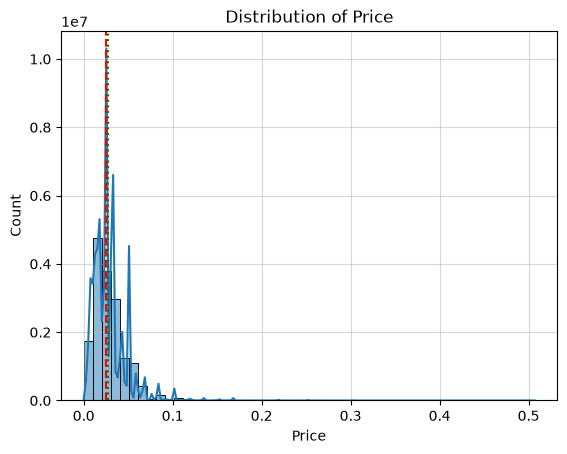

In [6]:
sns.histplot(df['price'],bins=50,kde=True)
plt.axvline(df['price'].median(),color='red',linestyle='--', label='Median')
plt.axvline(df['price'].mean(), color='green', linestyle=':', label='Mean')
plt.title('Distribution of Price')
plt.xlabel('Price')
plt.grid(True, alpha=0.5)
plt.show()


In [7]:
category_counts = df['product_group_name'].value_counts()

print(category_counts)


product_group_name
Garment Upper body       6504648
Garment Lower body       3640857
Garment Full body        1834274
Swimwear                 1395575
Underwear                1265479
Accessories               816234
Shoes                     399769
Socks & Tights            335178
Nightwear                 175883
Unknown                    23081
Bags                        3056
Items                       1684
Furniture                    456
Cosmetic                     418
Underwear/nightwear          245
Garment and Shoe care         64
Interior textile              29
Name: count, dtype: int64


In [8]:
category_revenue = df.groupby('product_group_name')['price'].sum()
print(category_revenue)

product_group_name
Accessories               12872.000237
Bags                        103.919695
Cosmetic                      2.328915
Furniture                     3.514305
Garment Full body         67792.429237
Garment Lower body       118622.755678
Garment Upper body       173904.623475
Garment and Shoe care         0.689492
Interior textile              0.312000
Items                        19.891441
Nightwear                  4385.852288
Shoes                     15630.562237
Socks & Tights             3837.860949
Swimwear                  31619.710695
Underwear                 26246.506542
Underwear/nightwear           6.888864
Unknown                     555.031915
Name: price, dtype: float64


In [9]:
comparison = pd.DataFrame({
  'count':category_counts,
  'revenue':category_revenue
}).sort_values('revenue',ascending=False)

print(comparison)

                         count        revenue
product_group_name                           
Garment Upper body     6504648  173904.623475
Garment Lower body     3640857  118622.755678
Garment Full body      1834274   67792.429237
Swimwear               1395575   31619.710695
Underwear              1265479   26246.506542
Shoes                   399769   15630.562237
Accessories             816234   12872.000237
Nightwear               175883    4385.852288
Socks & Tights          335178    3837.860949
Unknown                  23081     555.031915
Bags                      3056     103.919695
Items                     1684      19.891441
Underwear/nightwear        245       6.888864
Furniture                  456       3.514305
Cosmetic                   418       2.328915
Garment and Shoe care       64       0.689492
Interior textile            29       0.312000


In [10]:
df.groupby('product_group_name')['price'].describe()

,count,mean,std,min,25%,50%,75%,max
product_group_name,,,,,,,,
Accessories,816234.0,0.015770,0.011458,0.000051,0.008458,0.013542,0.018627,0.337288
Bags,3056.0,0.034005,0.008720,0.010831,0.030492,0.033881,0.033881,0.067780
Cosmetic,418.0,0.005572,0.002086,0.000525,0.004051,0.005068,0.006763,0.010153
Furniture,456.0,0.007707,0.007227,0.002169,0.004051,0.005407,0.008458,0.050831
Garment Full body,1834274.0,0.036959,0.021203,0.000407,0.024797,0.033881,0.049169,0.506780
Garment Lower body,3640857.0,0.032581,0.017012,0.000186,0.021593,0.032186,0.042356,0.422034
Garment Upper body,6504648.0,0.026735,0.021470,0.000017,0.013542,0.022017,0.033881,0.506780
Garment and Shoe care,64.0,0.010773,0.005291,0.003542,0.005068,0.013356,0.016407,0.016932
Interior textile,29.0,0.010759,0.002023,0.007525,0.009407,0.010153,0.013542,0.013542


/var/folders/d7/bj2588ts4pld6428khjst_lh0000gn/T/ipykernel_2362/2063552818.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_counts.values, y=category_counts.index,palette='Set2')


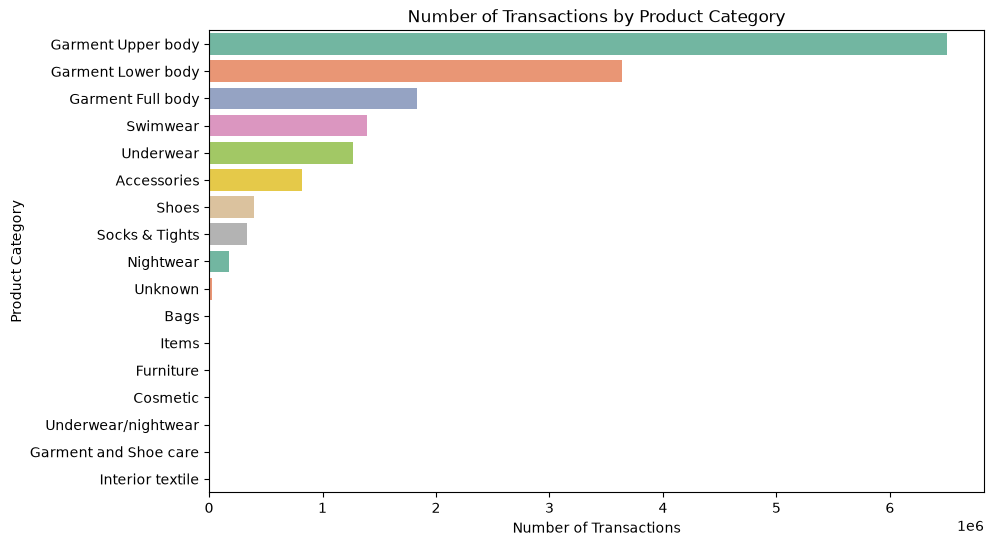

In [11]:


plt.figure(figsize=(10, 6))
sns.barplot(x=category_counts.values, y=category_counts.index,palette='Set2')
plt.title('Number of Transactions by Product Category')
plt.xlabel('Number of Transactions')
plt.ylabel('Product Category')
plt.show()

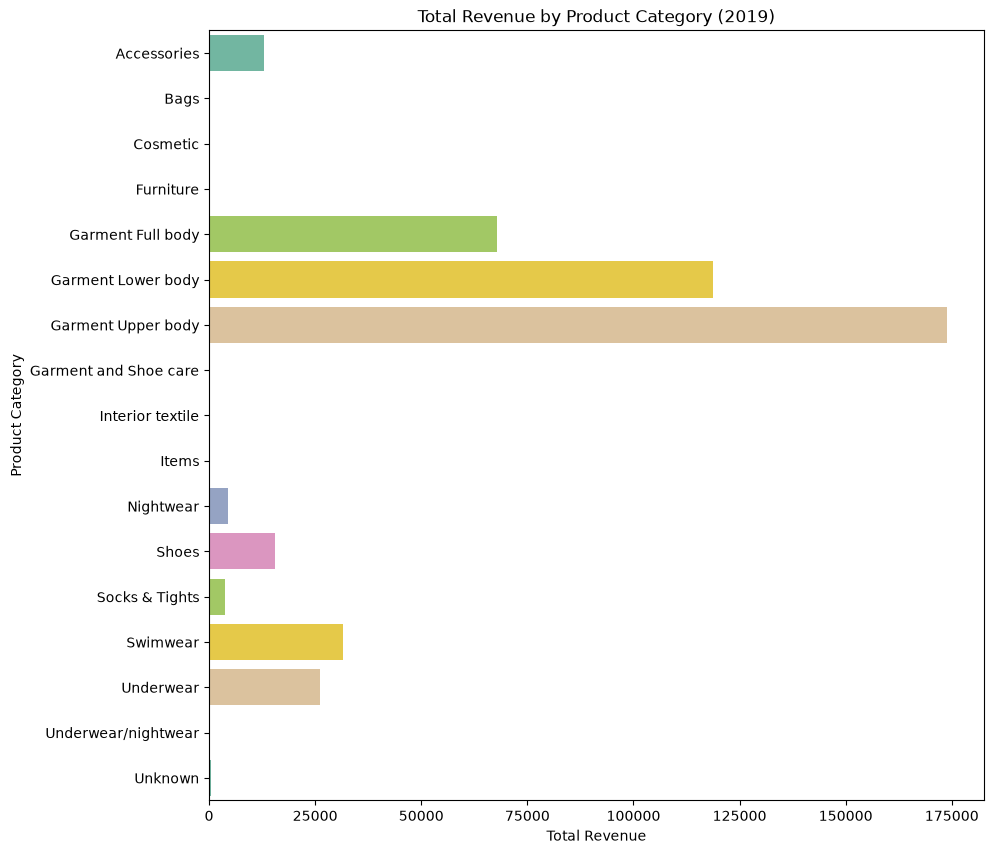

In [12]:
plt.figure(figsize=(10, 10))
sns.barplot(x=category_revenue.values, y=category_revenue.index, hue=category_revenue.index, palette='Set2', legend=False)
plt.title('Total Revenue by Product Category (2019)')
plt.xlabel('Total Revenue')
plt.ylabel('Product Category')
plt.show()

In [13]:
product_revenue = df.groupby('prod_name')['price'].sum().sort_values(ascending=False)
print(product_revenue.head())

prod_name
Jade HW Skinny Denim TRS      3070.508627
Luna skinny RW                2122.424593
Shaping Skinny H.W            1614.769203
Push Up Jegging L.W           1163.673915
Embrace S.Skinny Ankle H.W    1147.140847
Name: price, dtype: float64


In [14]:
product_category_revenue = df.groupby(['prod_name', 'product_group_name'])['price'].sum().sort_values(ascending=False)
product_category_revenue.head(20)

prod_name                    product_group_name
Jade HW Skinny Denim TRS     Garment Lower body    3070.508627
Luna skinny RW               Garment Lower body    2122.424593
Shaping Skinny H.W           Garment Lower body    1614.769203
Push Up Jegging L.W          Garment Lower body    1163.673915
Embrace S.Skinny Ankle H.W   Garment Lower body    1147.140847
Shaping Skinny R.W           Garment Lower body    1113.576373
Mariette Blazer              Garment Upper body    1075.435424
Femme (1)                    Garment Upper body    1002.491847
Despacito                    Garment Upper body     982.462831
Kanta slacks RW              Garment Lower body     981.325373
Simple as That Triangle Top  Swimwear               937.239068
SUPREME tights               Garment Lower body     926.369288
Perrie Slim Mom Denim TRS    Garment Lower body     923.645712
Julia RW Skinny Denim TRS    Garment Lower body     913.952034
Baraboom (1)                 Garment Upper body     816.589305
SUPREME

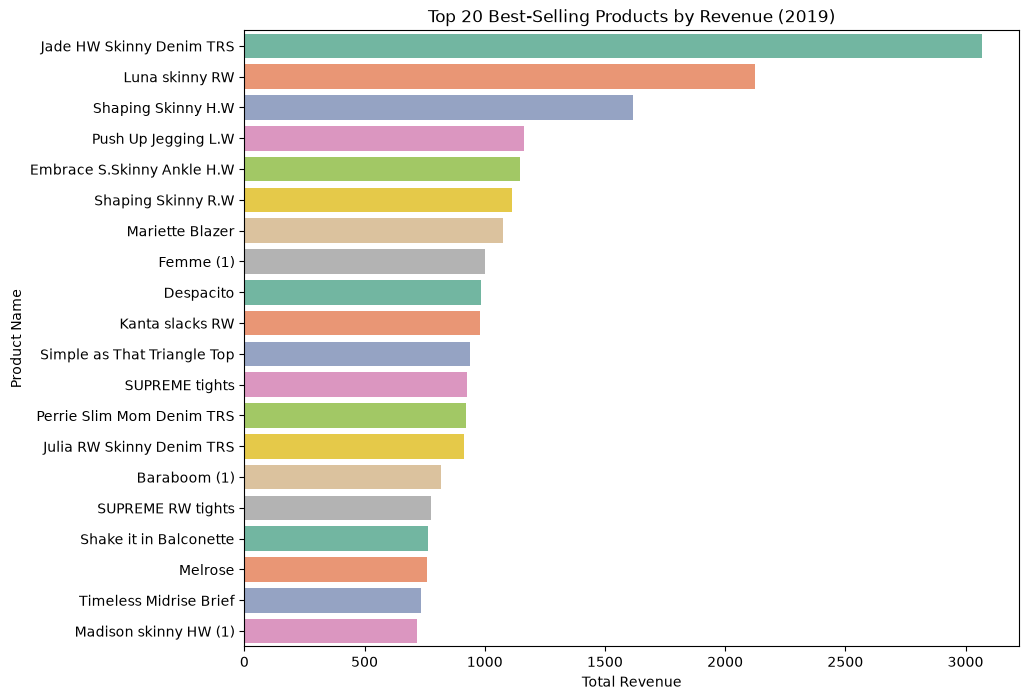

In [15]:
top_products = product_revenue.head(20)

plt.figure(figsize=(10, 8))
sns.barplot(x=top_products.values, y=top_products.index, hue=top_products.index, palette='Set2', legend=False)
plt.title('Top 20 Best-Selling Products by Revenue (2019)')
plt.xlabel('Total Revenue')
plt.ylabel('Product Name')
plt.show()

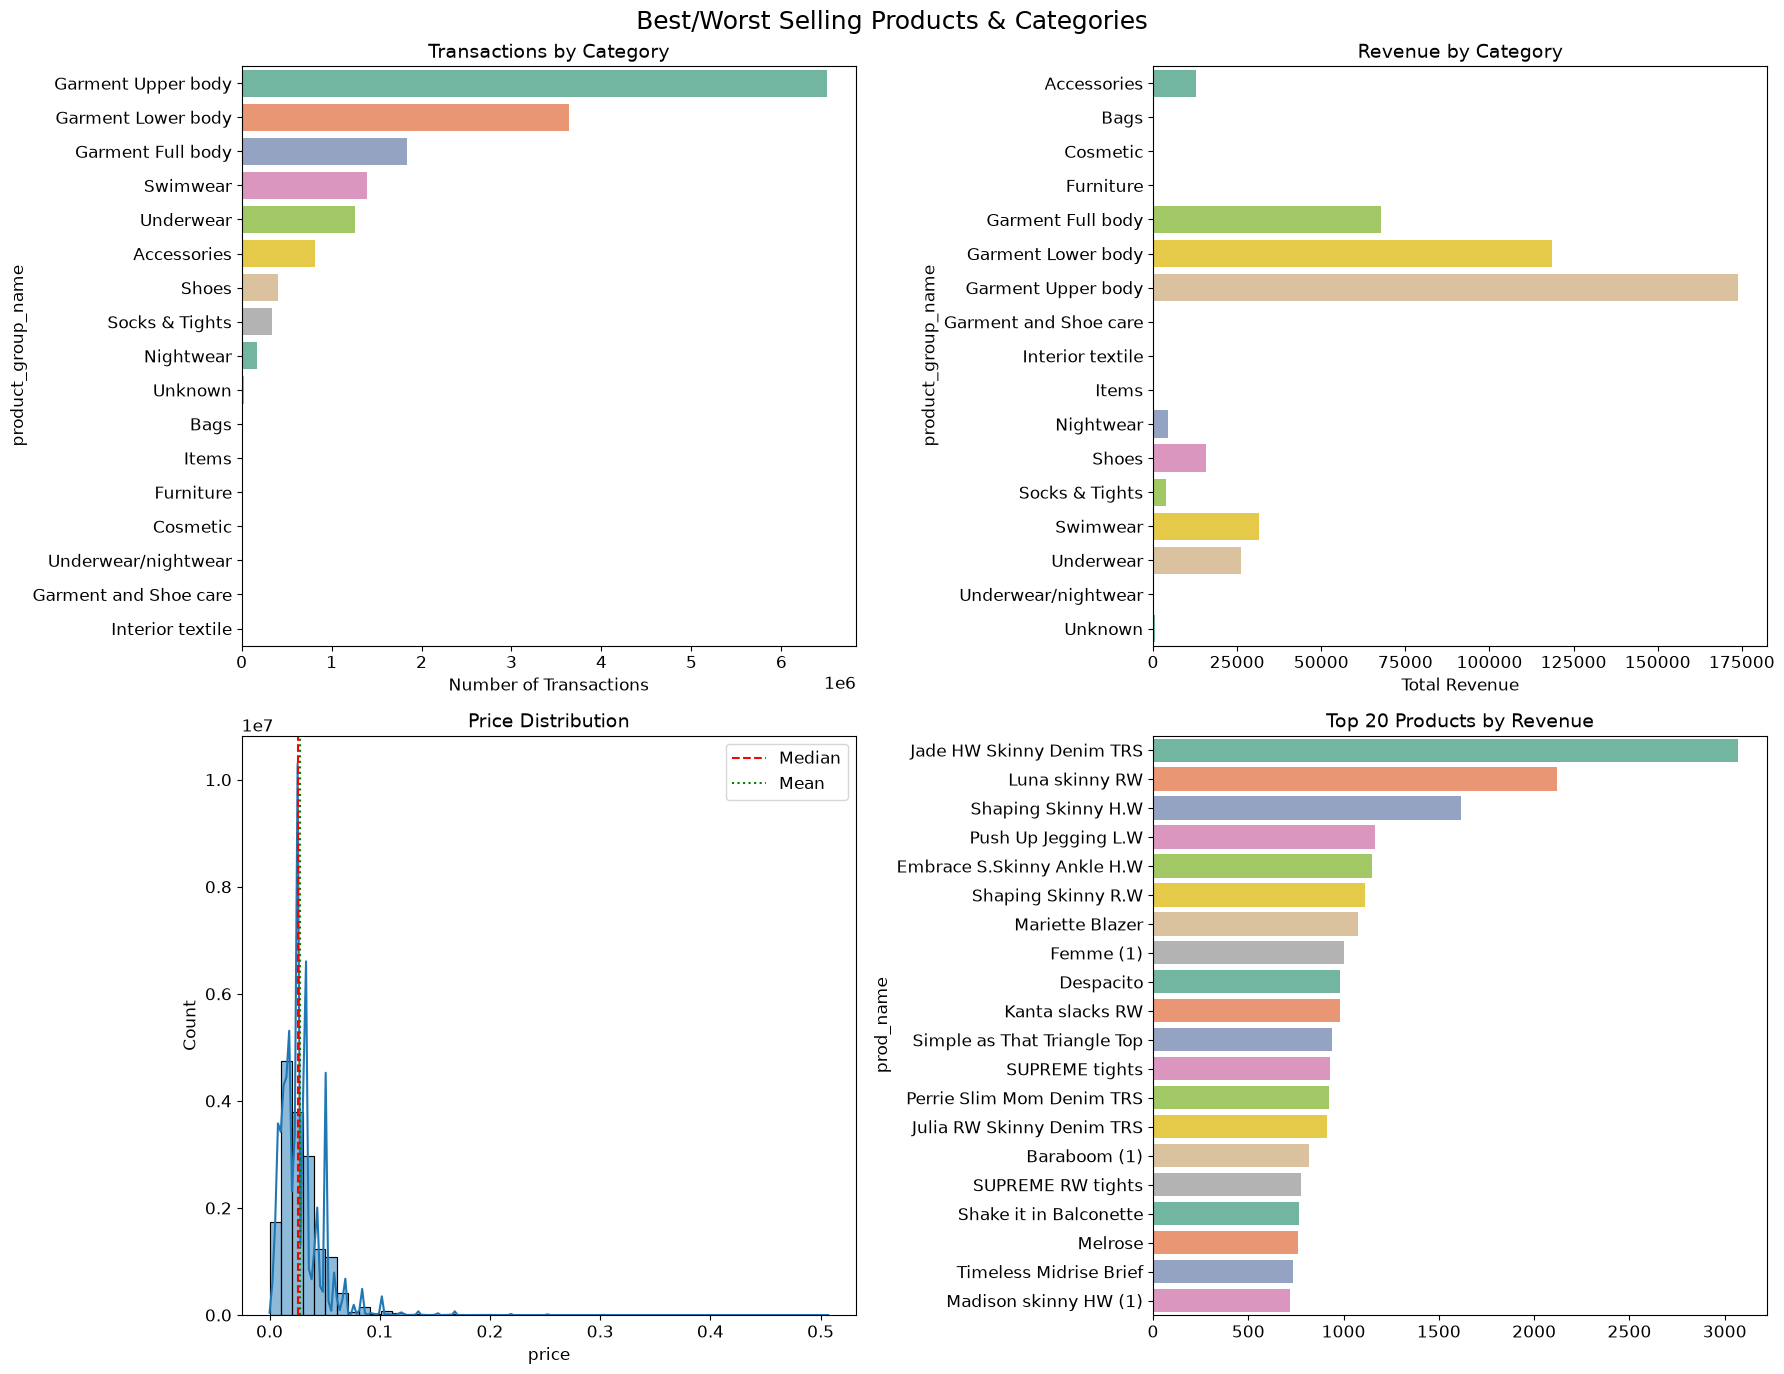

In [19]:
plt.rcParams.update({'font.size': 12})

fig, axes = plt.subplots(2, 2, figsize=(18, 14))

sns.barplot(x=category_counts.values, y=category_counts.index, hue=category_counts.index, palette='Set2', legend=False, ax=axes[0, 0])
axes[0, 0].set_title('Transactions by Category', fontsize=14)
axes[0, 0].set_xlabel('Number of Transactions')

sns.barplot(x=category_revenue.values, y=category_revenue.index, hue=category_revenue.index, palette='Set2', legend=False, ax=axes[0, 1])
axes[0, 1].set_title('Revenue by Category', fontsize=14)
axes[0, 1].set_xlabel('Total Revenue')

sns.histplot(df['price'], bins=50, kde=True, ax=axes[1, 0])
axes[1, 0].axvline(df['price'].median(), color='red', linestyle='--', label='Median')
axes[1, 0].axvline(df['price'].mean(), color='green', linestyle=':', label='Mean')
axes[1, 0].set_title('Price Distribution', fontsize=14)
axes[1, 0].legend()

sns.barplot(x=top_products.values, y=top_products.index, hue=top_products.index, palette='Set2', legend=False, ax=axes[1, 1])
axes[1, 1].set_title('Top 20 Products by Revenue', fontsize=14)

plt.suptitle('Best/Worst Selling Products & Categories', fontsize=18)
plt.tight_layout()
plt.savefig('reports/goal1_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()

## Findings: Best/Worst Selling Categories (2019)
Price is right-skewed across the dataset. Most items are low-priced, with a small number of high-priced items pulling the mean above the median.

Garment Upper body leads in both transaction volume (6.5M) and total revenue (~174K). However, its average price per item (0.027) is lower than Garment Full body (0.037) and Bags (0.034). The revenue lead comes from volume not price.

Accessories has more transactions than Shoes (816K vs 400K), but Shoes generates higher total revenue (15.6K vs 12.9K). Shoes are priced higher per item on average, which offsets the lower sales count.



At the product level, Garment Lower body accounts for most of the top 20 best-sellers, driven by a few standout denim styles. Garment Upper body's category-level lead comes from broad, consistent performance across many products. Swimwear, a mid-tier category overall, has 4 products in the top 20, stronger individual performance than its category ranking suggests.